# Fidelity heatmap: training-run OOD suites

Mean fidelity per spectral state for every out-of-distribution suite evaluated in `s06_evaluation.py` of the most recent run (everything except `ID_test`). Each column is one `category / family` pair; the header row gives its distribution role. No model is loaded and no inference is performed.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

In [2]:
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/"outputs").is_dir() and (p/"stages").is_dir())
MODE = "STANDARD"
ROUTE_PREFERENCE = ("physics_selected", "direct_topology")  # first available route is plotted
file = "per_state_output_metrics.csv"
runs = [p for p in (ROOT/"outputs").glob(f"true_jepa_{MODE.lower()}_*") if (p/file).exists()]
run = max(runs, key=lambda p: (p/file).stat().st_mtime)
d = pd.read_csv(run/file)
ROUTE = next(r for r in ROUTE_PREFERENCE if r in set(d.output_route))
d = d.query("output_route == @ROUTE and category != 'ID_test'")
print(run.name, ROUTE, {"categories": d.category.nunique(), "hamiltonians": d.group_id.nunique()})

true_jepa_standard_fbc1677c_aee2f53f physics_selected {'categories': 20, 'hamiltonians': 334}


In [3]:
ROLE_ORDER = ["unseen_functional_form_ood", "seen_basis_reparameterization_diagnostic", "parameter_extrapolation_ood",
              "bracketed_parameter_interpolation", "near_continuum_challenge", "operator_covariance_or_resolution_challenge",
              "same_training_family_challenge"]
summary = (d.groupby(["distribution_role", "category", "family"])
             .agg(hamiltonians=("group_id", "nunique"), fidelity=("fidelity", "mean")).reset_index())
summary["role_rank"] = summary.distribution_role.map({r: i for i, r in enumerate(ROLE_ORDER)}).fillna(len(ROLE_ORDER))
summary = summary.sort_values(["role_rank", "fidelity"], ascending=[True, False])
columns = list(zip(summary.category, summary.family))
x = d.groupby(["state", "category", "family"]).fidelity.mean().unstack(["category", "family"])[columns]
summary.drop(columns="role_rank")

,distribution_role,category,family,hamiltonians,fidelity
24,unseen_functional_form_ood,unseen_analytical_functional_forms,scarf_ii,64,0.999873
22,unseen_functional_form_ood,unseen_analytical_functional_forms,cosh_well,64,0.996559
23,unseen_functional_form_ood,unseen_analytical_functional_forms,eckart,64,0.093832
21,seen_basis_reparameterization_diagnostic,seen_basis_reparameterization,rosen_morse_ii,16,0.999885
9,parameter_extrapolation_ood,single_parameter_extrapolation,harmonic,1,0.999949
8,parameter_extrapolation_ood,joint_parameter_extrapolation,fourier_random,1,0.999925
10,parameter_extrapolation_ood,single_parameter_extrapolation,morse,1,0.999896
7,parameter_extrapolation_ood,joint_parameter_extrapolation,double_well,1,0.999729
0,bracketed_parameter_interpolation,within_range_unseen_parameter_interpolation,harmonic,1,0.999949
1,near_continuum_challenge,near_continuum_states,radial_coulomb,1,0.966262


In [4]:
def heatmap(x, title, name, annotate_below=.80):
    labels = [f"{c.replace('_', ' ')} / {f.replace('_', ' ')}" if c.replace("_", "") != f.replace("_", "") else c.replace("_", " ")
              for c, f in x.columns]
    labels = [f"{l} (N={summary.set_index(['category', 'family']).hamiltonians[col]})" for l, col in zip(labels, x.columns)]
    fig, ax = plt.subplots(figsize=(max(8.0, .36*x.shape[1]), 7.0))
    im = ax.imshow(x, origin="lower", aspect="auto", cmap="viridis", vmin=0, vmax=1)
    ax.set(title=f"{title} ({ROUTE})", xlabel="OOD suite / family", ylabel=r"Spectral index $n$",
           xticks=range(x.shape[1]), xticklabels=labels, yticks=range(x.shape[0]), yticklabels=x.index)
    plt.setp(ax.get_xticklabels(), rotation=90, fontsize=6.5)
    for j, role in enumerate(summary.distribution_role):  # role boundaries
        if j and role != summary.distribution_role.iloc[j-1]: ax.axvline(j-.5, color="white", lw=1.2)
    for (i, j), v in np.ndenumerate(x.to_numpy()):
        if np.isfinite(v) and v < annotate_below:
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6, color="white")
    fig.colorbar(im, ax=ax, label="Mean fidelity"); fig.tight_layout()
    for ext in ("png", "pdf"): fig.savefig(ROOT/"results"/run.name/"02_figures"/f"fidelity_heatmap_{name}.{ext}", dpi=200, bbox_inches="tight")
    plt.show()
    x.to_csv(ROOT/"results"/run.name/"02_figures"/f"fidelity_heatmap_{name}.csv")

In [5]:
plt.rcParams.update({"font.family": "serif", "font.size": 8, "axes.linewidth": .8})
heatmap(x, "Regular: training-run OOD suites", "regular_training_ood")

KeyboardInterrupt: 

In [ ]:
assert "ID_test" not in set(d.category) and x.notna().any().all()
print("TRAINING-OOD HEATMAP AUDIT: PASS", {"mode": MODE, "route": ROUTE, "run": run.name, "columns": x.shape[1]})

TRAINING-OOD HEATMAP AUDIT: PASS {'mode': 'STANDARD', 'route': 'physics_selected', 'run': 'true_jepa_standard_fbc1677c_aee2f53f', 'columns': 25}


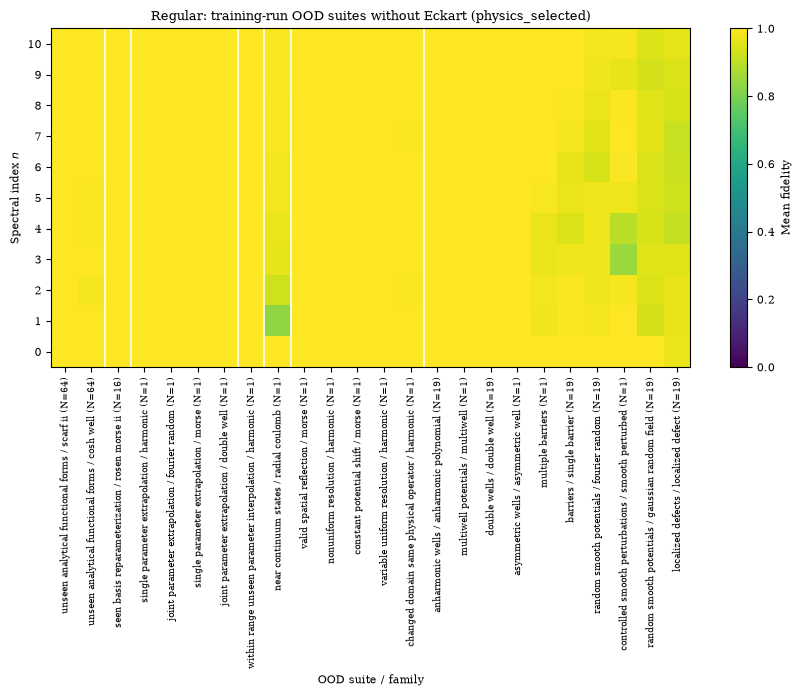

TRAINING-OOD HEATMAP WITHOUT ECKART: PASS {'columns': 24}


In [ ]:
# Same heatmap without Eckart. `heatmap` reads the global `summary` for N labels and role
# boundaries, so it is filtered together with `x` and restored afterwards.
EXCLUDED_FAMILIES = {"eckart"}
summary_all, x_all = summary, x
summary = summary_all[~summary_all.family.isin(EXCLUDED_FAMILIES)]
x_no_eckart = x_all[[col for col in x_all.columns if col[1] not in EXCLUDED_FAMILIES]]
try:
    heatmap(x_no_eckart, "Regular: training-run OOD suites without Eckart", "regular_training_ood_no_eckart")
finally:
    summary, x = summary_all, x_all
assert not any(family in EXCLUDED_FAMILIES for _, family in x_no_eckart.columns)
print("TRAINING-OOD HEATMAP WITHOUT ECKART: PASS", {"columns": x_no_eckart.shape[1]})
